# Question 1a

In [17]:
import numpy as np
import pandas as pd
from scipy.io import mmread

# Path to the data
data_dir = "filtered_gene_bc_matrices/GRCh38"

# Load genes and cell barcodes
genes = pd.read_csv(
    f"{data_dir}/genes.tsv",
    sep="\t",
    header=None
)

barcodes = pd.read_csv(
    f"{data_dir}/barcodes.tsv",
    sep="\t",
    header=None
)

# Load sparse matrix
matrix = mmread(f"{data_dir}/matrix.mtx")

print("Sparse matrix shape:", matrix.shape)
print("Number of genes:", len(genes))
print("Number of cells:", len(barcodes))

Sparse matrix shape: (33694, 4340)
Number of genes: 33694
Number of cells: 4340


In [18]:
# construct a dense matrix of genes by cells from the sparse list
X = matrix.toarray()
print("Dense matrix shape:", X.shape)
print("Number of genes:", X.shape[0])
print("Number of cells:", X.shape[1])

Dense matrix shape: (33694, 4340)
Number of genes: 33694
Number of cells: 4340


The dense matrix shape is 33694 rows and 4340 columns. 33694 genes and 4340 cells. 

# Question 1b

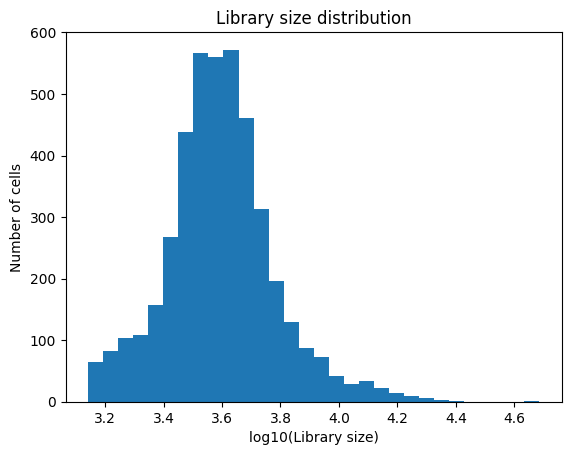

In [19]:
import matplotlib.pyplot as plt

# Total counts for each cell
library_size = X.sum(axis=0)

# Log10 library size
log_library_size = np.log10(library_size)

# Plot histogram
plt.hist(log_library_size, bins=30)
plt.xlabel("log10(Library size)")
plt.ylabel("Number of cells")
plt.title("Library size distribution")
plt.show()

In [20]:
Q1 = np.percentile(log_library_size, 25)
Q3 = np.percentile(log_library_size, 75)

IQR = Q3 - Q1
threshold = Q1 - 1.5 * IQR

print("Filtering threshold:", threshold)
print("Cells removed:", (log_library_size < threshold).sum())

Filtering threshold: 3.181986631906989
Cells removed: 48


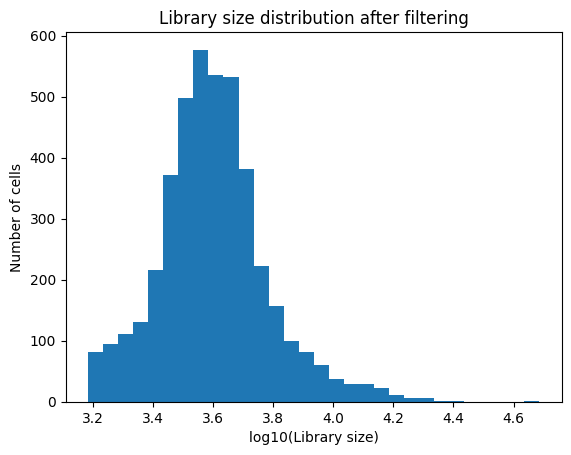

In [21]:
# Filter cells
keep = log_library_size >= threshold

X_filtered = X[:, keep]

# Library sizes after filtering
library_size_filtered = X_filtered.sum(axis=0)
log_library_size_filtered = np.log10(library_size_filtered)

# Plot after filtering
plt.hist(log_library_size_filtered, bins=30)
plt.xlabel("log10(Library size)")
plt.ylabel("Number of cells")
plt.title("Library size distribution after filtering")
plt.show()

In [22]:
median_library_size = np.median(library_size_filtered)

print("Cells remaining:", X_filtered.shape[1])
print("Median library size:", median_library_size)

Cells remaining: 4292
Median library size: 3892.0


In [23]:
# 20% more stringent
threshold_more = threshold * 1.20

# 20% less stringent
threshold_less = threshold * 0.80

# Number of cells removed under each threshold
removed_more = (log_library_size < threshold_more).sum()
removed_less = (log_library_size < threshold_less).sum()

# Median library size for each case
median_more = np.median(
    library_size[log_library_size >= threshold_more]
)

median_less = np.median(
    library_size[log_library_size >= threshold_less]
)

print("Original threshold:", threshold)
print("Original median:", median_library_size)

print("20% more stringent:")
print("Threshold:", threshold_more)
print("Cells removed:", removed_more)
print("Median:", median_more)

print("20% less stringent:")
print("Threshold:", threshold_less)
print("Cells removed:", removed_less)
print("Median:", median_less)

Original threshold: 3.181986631906989
Original median: 3892.0
20% more stringent:
Threshold: 3.8183839582883867
Cells removed: 3917
Median: 8502.0
20% less stringent:
Threshold: 2.5455893055255916
Cells removed: 0
Median: 3866.5


In [24]:
# sensitivity analysis: convert from log10 scale to original
threshold_counts = 10**threshold

threshold_more = threshold_counts * 1.20
threshold_less = threshold_counts * 0.80

keep_more = library_size >= threshold_more
keep_less = library_size >= threshold_less

median_more = np.median(library_size[keep_more])
median_less = np.median(library_size[keep_less])

print("Original threshold:", threshold_counts)
print("Original median:", median_library_size)

print("20% more stringent:")
print("Cells removed:", (~keep_more).sum())
print("Median:", median_more)

print("20% less stringent:")
print("Cells removed:", (~keep_less).sum())
print("Median:", median_less)

Original threshold: 1520.5007262182596
Original median: 3892.0
20% more stringent:
Cells removed: 184
Median: 3949.0
20% less stringent:
Cells removed: 0
Median: 3866.5


The log10 library-size distribution is unimodal, with most cells concentrated around the main peak and a small tail of cells with lower library sizes. A log-normal distribution would be a reasonable fit for the library-size data.
I decided to filter the low-library-size cells because they have much less expression data than the main group of cells. I used the lower Tukey fence, Q_1-1.5(IQR), as a data-driven cutoff rather than using a threshold from Scanpy or Seurat. This gave a cutoff of log10(library size)=3.182, or about 1,521 counts. This removed 48 cells, leaving 4,292 cells. After filtering, the median library size was 3,892 counts.
For the sensitivity analysis, a 20% more stringent threshold removed 184 cells and gave a median of 3,949, while a 20% less stringent threshold removed 0 cells and gave a median of 3,866.5. The median therefore changed by only about 1.46% and 0.66%, respectively. This suggests that the original filtering decision was not very consequential for the median library size, although a stricter cutoff did remove substantially more cells.